In [ ]:
%pip install pandas networkx matplotlib

In [5]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

nodes = pd.read_csv("Data/os_maias_ground_truth_nodes.csv")
edges = pd.read_csv("Data/os_maias_ground_truth_edges.csv")

In [6]:
G = nx.Graph()

# Add characters as nodes
for _, row in nodes.iterrows():
    G.add_node(row["id"], name=row["name"])

# Add interactions as edges
for _, row in edges.iterrows():
    G.add_edge(row["source"], row["target"],
               interaction_type=row["interaction_type"])

In [ ]:
G_connected = G.subgraph(
    [n for n in G.nodes if G.degree(n) > 0]
).copy()

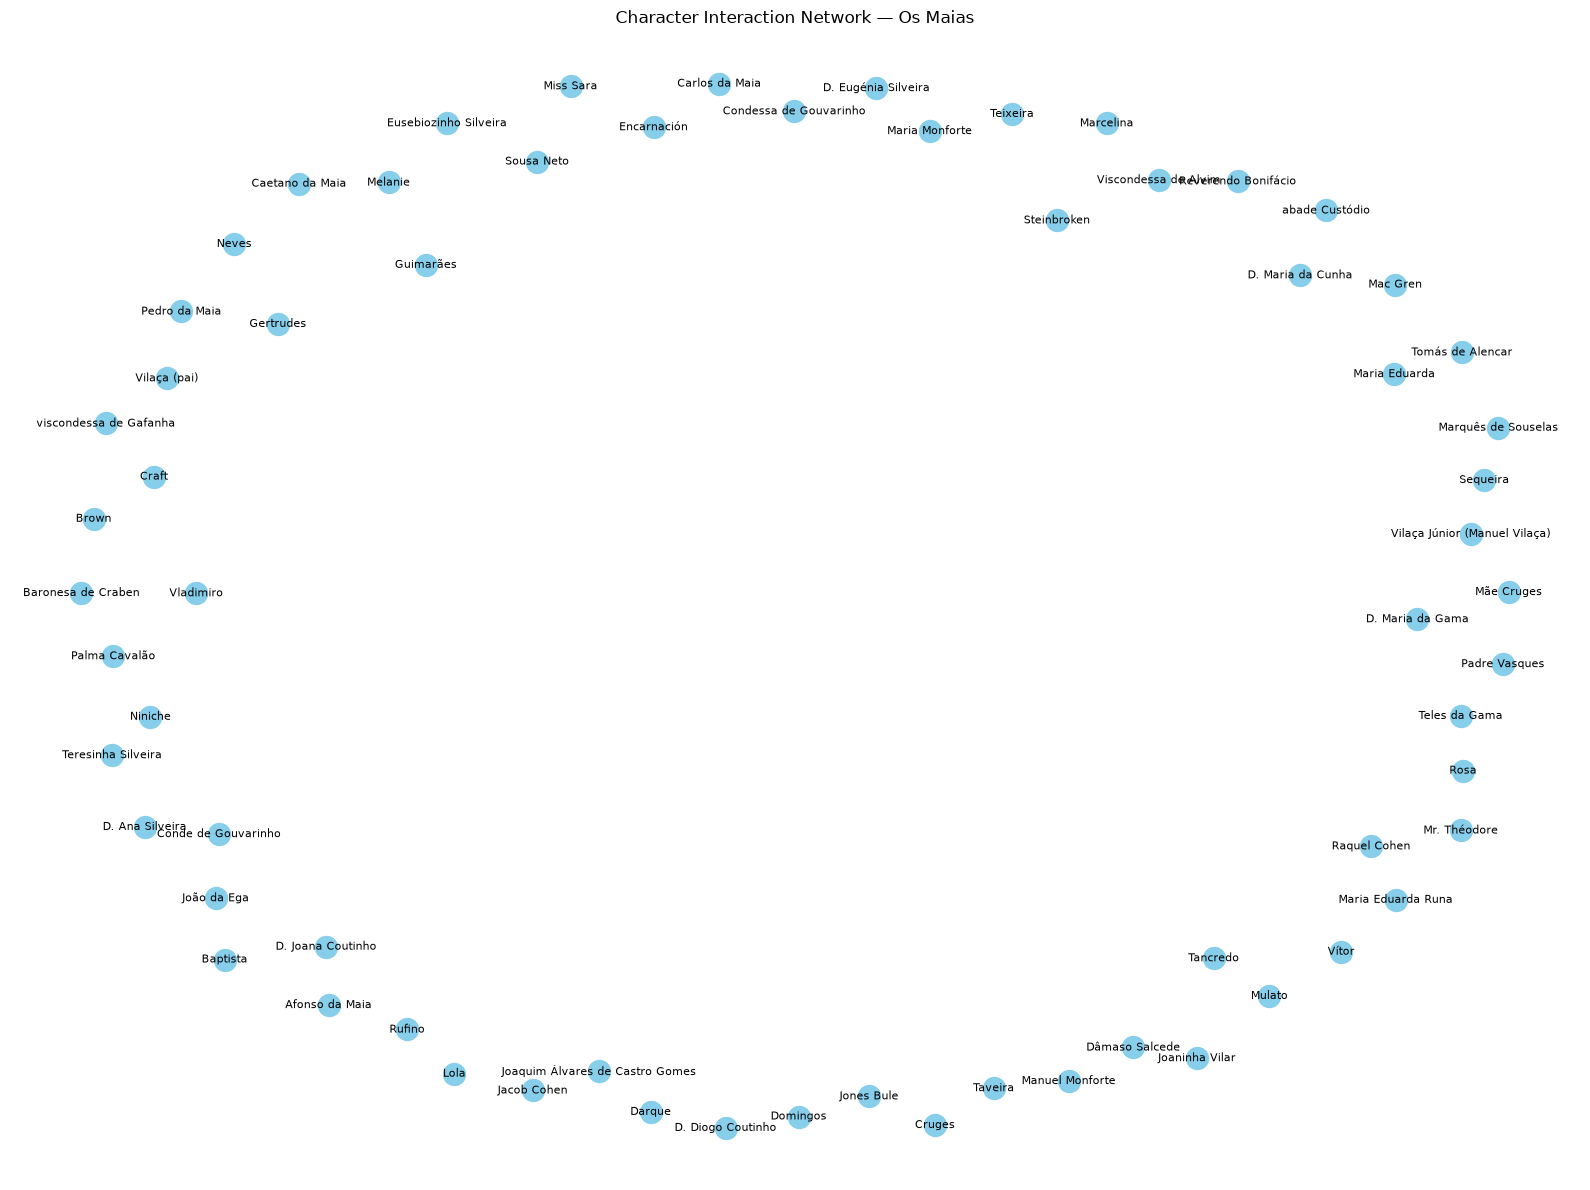

In [4]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42, k=0.8)

nx.draw_networkx_edges(G, pos, alpha=0.3, width=1)
nx.draw_networkx_nodes(G, pos, node_size=250, node_color="skyblue")

labels = nx.get_node_attributes(G, "name")
nx.draw_networkx_labels(G, pos, labels, font_size=8)

plt.title("Character Interaction Network — Os Maias")
plt.axis("off")
plt.tight_layout()
plt.show()